# Rock–Paper–Scissors Image Classifier using ANN

### Week 7 Deep Learning — Day 2 Project

**Goal:** Train a simple Artificial Neural Network (ANN) to classify hand gestures into:

- 🪨 Rock
- 📄 Paper
- ✂️ Scissors

Then save the trained model so it can later be used by a **FastAPI backend** and a **Streamlit interface**.

> **Important:** This notebook deliberately uses an ANN, not a CNN. We resize each image and flatten its pixels into a 1D vector. This is useful for teaching because students can clearly see how an ANN handles image data. Later, CNNs will solve the image problem more naturally.


## 1. Dataset

We will use the **Rock Paper Scissors dataset by Laurence Moroney**. TensorFlow Datasets lists 2,520 training examples and 372 test examples, with 3 classes and RGB images of shape 300×300×3. citeturn1search1

### Direct dataset

`https://storage.googleapis.com/learning-datasets/rps.zip`

The ZIP contains:

```text
rps/
├── paper/
├── rock/
└── scissors/
```

The dataset is also documented by TensorFlow Datasets:

https://www.tensorflow.org/datasets/catalog/rock_paper_scissors


In [1]:
# Install / import libraries
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix


In [6]:
DATA_DIR = Path(r"D:\AI\Courses\Huawei_HCCDA_AI_Course\week_07\sunday\datasets\rps\rps")

classes = os.listdir(DATA_DIR)

In [14]:
classes

['paper', 'rock', 'scissors']

In [13]:
list(enumerate(classes))

[(0, 'paper'), (1, 'rock'), (2, 'scissors')]

In [16]:
paths = []

for cls in classes:
    cls_path = DATA_DIR / cls
    paths.append(os.listdir(cls_path))

In [18]:
len(paths)

3

In [27]:
img_path = DATA_DIR / classes[0] / paths[0][0]

In [30]:
img = plt.imread(img_path)

In [31]:
img.shape

(300, 300, 4)

In [36]:
class_dir = DATA_DIR/classes[0]
list(class_dir.glob("*"))

[WindowsPath('D:/AI/Courses/Huawei_HCCDA_AI_Course/week_07/sunday/datasets/rps/rps/paper/paper01-000.png'),
 WindowsPath('D:/AI/Courses/Huawei_HCCDA_AI_Course/week_07/sunday/datasets/rps/rps/paper/paper01-001.png'),
 WindowsPath('D:/AI/Courses/Huawei_HCCDA_AI_Course/week_07/sunday/datasets/rps/rps/paper/paper01-002.png'),
 WindowsPath('D:/AI/Courses/Huawei_HCCDA_AI_Course/week_07/sunday/datasets/rps/rps/paper/paper01-003.png'),
 WindowsPath('D:/AI/Courses/Huawei_HCCDA_AI_Course/week_07/sunday/datasets/rps/rps/paper/paper01-004.png'),
 WindowsPath('D:/AI/Courses/Huawei_HCCDA_AI_Course/week_07/sunday/datasets/rps/rps/paper/paper01-005.png'),
 WindowsPath('D:/AI/Courses/Huawei_HCCDA_AI_Course/week_07/sunday/datasets/rps/rps/paper/paper01-006.png'),
 WindowsPath('D:/AI/Courses/Huawei_HCCDA_AI_Course/week_07/sunday/datasets/rps/rps/paper/paper01-007.png'),
 WindowsPath('D:/AI/Courses/Huawei_HCCDA_AI_Course/week_07/sunday/datasets/rps/rps/paper/paper01-008.png'),
 WindowsPath('D:/AI/Courses/

In [32]:
# Check folders and number of images

classes = ["paper", "rock", "scissors"]

for class_name in classes:
    class_dir = DATA_DIR / class_name
    images = list(class_dir.glob("*"))
    print(f"{class_name:10s}: {len(images)} images")


paper     : 840 images
rock      : 840 images
scissors  : 840 images


## 3. Display sample images

Before training a computer vision model, always inspect the data.

In [37]:
list(enumerate(classes))

[(0, 'paper'), (1, 'rock'), (2, 'scissors')]

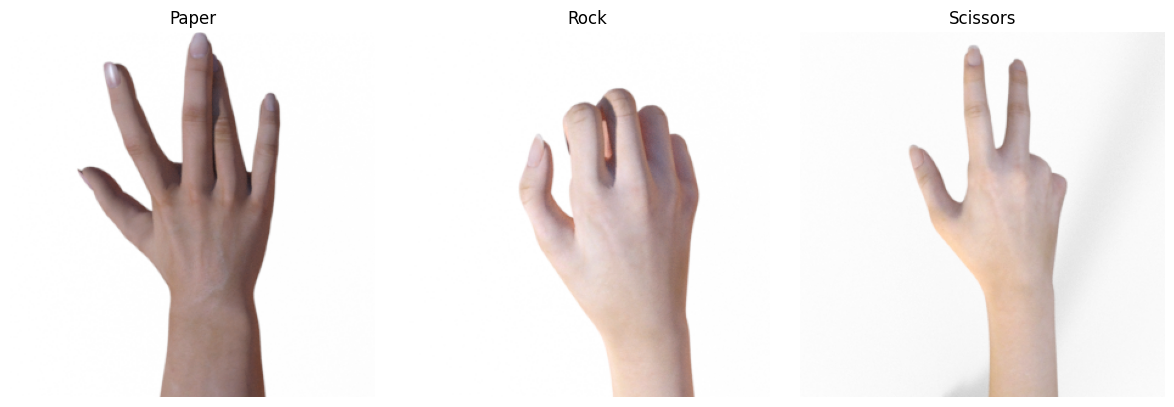

In [38]:
plt.figure(figsize=(12, 4))

for i, class_name in enumerate(classes):
    class_dir = DATA_DIR / class_name
    image_path = list(class_dir.glob("*"))[0]

    image = plt.imread(image_path)

    plt.subplot(1, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name.capitalize())
    plt.axis("off")

plt.tight_layout()
plt.show()


## 4. Image preprocessing

Our ANN cannot directly consume an image such as:

```text
300 × 300 × 3
```

We will:

1. Resize each image to **64 × 64**
2. Normalize pixels from **0–255 → 0–1**
3. Flatten the image inside the ANN

So the ANN receives:

```text
64 × 64 × 3 = 12,288 numbers
```

This is a large input vector, but it is manageable for a classroom demonstration.

> **Why not use the original 300×300 images?**  
> Because flattening 300×300×3 produces 270,000 input values, making a fully connected ANN unnecessarily large for this teaching project.


In [44]:
np.random.seed(43)
np.random.randint(0,100, 100, )

array([68, 64, 49, 21, 58, 16, 51, 17, 59, 91, 66, 30, 87, 64, 35, 50, 75,
       89, 65, 34, 75, 66, 99,  4, 36, 76, 88, 47, 32, 74, 60, 73, 34, 48,
       52, 68, 28, 73,  7, 61, 84, 47, 53, 32,  3, 34, 41, 25, 29, 26, 53,
       85, 21, 74, 27, 58,  7, 95, 61, 99, 51, 34, 46, 52, 18, 23,  3, 70,
       24, 51,  6, 44, 87, 36, 85, 14, 83, 85, 40, 83, 85, 27, 42, 49, 70,
       16, 16, 78, 63, 28, 59, 31, 81, 33,  5, 13,  8, 64, 51, 54],
      dtype=int32)

In [ ]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 32
SEED = 42

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=SEED
)

validation_generator = datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

print("Class indices:", train_generator.class_indices)


Found 2016 images belonging to 3 classes.
Found 504 images belonging to 3 classes.
Class indices: {'paper': 0, 'rock': 1, 'scissors': 2}


In [47]:
for images, labels in train_generator:
    images = images
    labels= labels
    break

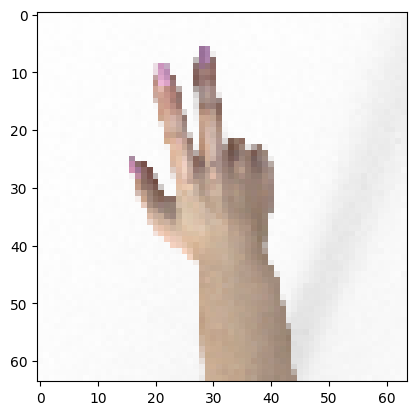

In [53]:
plt.imshow(images[0])

In [50]:
labels

array([[0., 0., 1.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [0., 0., 1.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 1., 0.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       [0., 0., 1.],
       [1., 0., 0.]], dtype=float32)

## 5. Understand the input shape

Because the images are RGB:

```text
64 × 64 × 3
```

The ANN will flatten this into:

```text
64 × 64 × 3 = 12,288
```

input values.

The output has **3 neurons**:

```text
Paper
Rock
Scissors
```

Because this is a multiclass problem, the output layer will use **softmax**.

In [54]:
input_size = 64 * 64 * 3
print("Flattened input size:", input_size)
print("Number of classes:", train_generator.num_classes)


Flattened input size: 12288
Number of classes: 3


## 6. Build the ANN

Architecture:

```text
64 × 64 × 3 image
        ↓
      Flatten
        ↓
    Dense(128)
        ↓
       ReLU
        ↓
     Dense(64)
        ↓
       ReLU
        ↓
      Dense(3)
        ↓
     Softmax
        ↓
Paper / Rock / Scissors
```

This is intentionally a simple ANN for teaching. A CNN would normally be a better architecture for image classification.

In [67]:
model = Sequential([
    Flatten(input_shape=(64, 64, 3)),

    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dense(3, activation="softmax")
])

model.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │       786,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 788,675 (3.01 MB)

 Trainable params: 788,675 (3.01 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Compile the model

For three-class classification:

- **Softmax** → produces probabilities for the 3 classes
- **Categorical crossentropy** → appropriate loss for one-hot multiclass labels
- **Adam** → optimizer
- **Accuracy** → evaluation metric

In [68]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


## 8. Train the ANN

Start with 10 epochs. Increase later if needed.

In [69]:
EPOCHS = 10

history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS
)


Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - accuracy: 0.3981 - loss: 2.2530 - val_accuracy: 0.4444 - val_loss: 1.1416
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - accuracy: 0.6824 - loss: 0.7391 - val_accuracy: 0.7560 - val_loss: 0.6866
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 79ms/step - accuracy: 0.8391 - loss: 0.4755 - val_accuracy: 0.6647 - val_loss: 0.7127
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - accuracy: 0.9354 - loss: 0.3160 - val_accuracy: 0.6667 - val_loss: 0.5909
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - accuracy: 0.9337 - loss: 0.2416 - val_accuracy: 0.5079 - val_loss: 1.0501
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - accuracy: 0.9408 - loss: 0.2125 - val_accuracy: 0.5893 - val_loss: 1.0676
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - accuracy: 0.9722 - loss: 0.1453 - val_accuracy: 0.6845 - val_loss: 0.8932
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - accuracy: 0.9281 - loss: 0.2160 - val_accuracy: 0.4782 - v

## 9. Plot training history

Look for the difference between training and validation performance.

Questions for students:

- Is the model learning?
- Does validation accuracy improve?
- Is there evidence of overfitting?
- What happens if we increase the number of epochs?

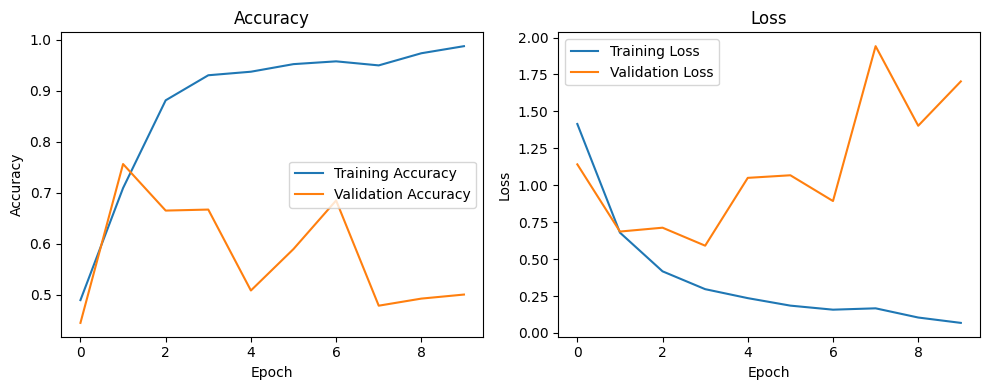

In [70]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss")

plt.tight_layout()
plt.show()


## 10. Evaluate the model

The validation generator acts as our held-out evaluation data for this classroom notebook.

In [71]:
loss, accuracy = model.evaluate(validation_generator)

print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.7151 - loss: 0.8436
Validation Loss: 1.7032
Validation Accuracy: 0.5000


## 11. Classification report and confusion matrix

This lets us see how the model performs for each class.

In [73]:
validation_generator.class_indices.keys()

dict_keys(['paper', 'rock', 'scissors'])

In [74]:
validation_generator.reset()

probabilities = model.predict(validation_generator)
y_pred = np.argmax(probabilities, axis=1)
y_true = validation_generator.classes

class_names = list(validation_generator.class_indices.keys())

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step
              precision    recall  f1-score   support

       paper       0.40      0.99      0.57       168
        rock       0.97      0.22      0.36       168
    scissors       1.00      0.29      0.44       168

    accuracy                           0.50       504
   macro avg       0.79      0.50      0.46       504
weighted avg       0.79      0.50      0.46       504

Confusion Matrix:
[[167   1   0]
 [131  37   0]
 [120   0  48]]


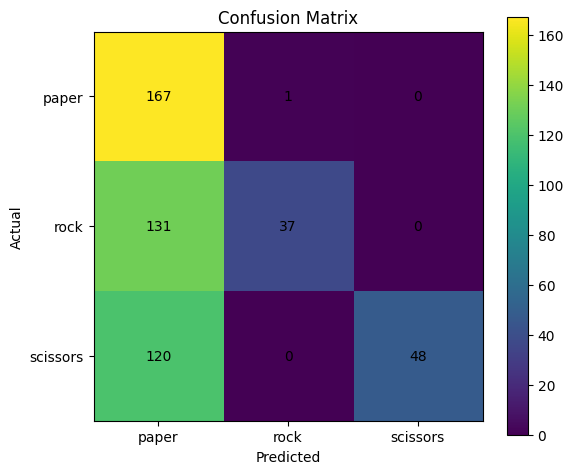

In [75]:
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(range(len(class_names)), class_names)
plt.yticks(range(len(class_names)), class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()


## 12. Save the trained model

This is the important step before building our API.

The model file will later be loaded by FastAPI.

In [76]:
MODEL_PATH = "rock_paper_scissors_ann.keras"

model.save(MODEL_PATH)

print("Model saved to:", MODEL_PATH)
print("File exists:", os.path.exists(MODEL_PATH))


Model saved to: rock_paper_scissors_ann.keras
File exists: True


## 13. Save the class names

The model outputs numbers. We need a mapping back to human-readable labels.

Example:

```text
0 → paper
1 → rock
2 → scissors
```

The exact mapping is determined by the directory names and should be saved rather than guessed.

In [77]:
train_generator.class_indices

{'paper': 0, 'rock': 1, 'scissors': 2}

In [81]:
{v:k for k, v in train_generator.class_indices.items()}


{0: 'paper', 1: 'rock', 2: 'scissors'}

In [82]:
import json

class_indices = train_generator.class_indices

# Convert {"paper": 0, "rock": 1, "scissors": 2}
# into {"0": "paper", "1": "rock", "2": "scissors"}
index_to_class = {
    str(index): class_name
    for class_name, index in class_indices.items()
}

with open("class_names.json", "w") as f:
    json.dump(index_to_class, f, indent=4)

print(index_to_class)


{'0': 'paper', '1': 'rock', '2': 'scissors'}


## 14. Test the saved model with a single image

This is almost exactly what our future FastAPI endpoint will do.

In [ ]:
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import load_img, img_to_array

loaded_model = load_model(MODEL_PATH)

with open("class_names.json", "r") as f:
    index_to_class = json.load(f)

def predict_image(image_path):
    image = load_img(image_path, target_size=IMG_SIZE)
    image_array = img_to_array(image) / 255.0

    # Add batch dimension:
    # (64, 64, 3) → (1, 64, 64, 3)
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = loaded_model.predict(image_array, verbose=0)[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_class = index_to_class[str(predicted_index)]
    confidence = float(probabilities[predicted_index])

    return predicted_class, confidence, probabilities


In [ ]:
# Test one image from each class

for class_name in classes:
    image_path = next((DATA_DIR / class_name).glob("*"))

    predicted_class, confidence, probabilities = predict_image(image_path)

    print(f"Actual:     {class_name}")
    print(f"Predicted:  {predicted_class}")
    print(f"Confidence: {confidence:.2%}")
    print(f"Scores:     {probabilities}")
    print("-" * 50)


## 15. Test your own image

Upload or copy an image of your hand into the notebook environment and provide its path.

**Important:** The training images have a particular visual style and background. A webcam image taken in a different environment may not perform as well. This is a useful real-world lesson about **distribution shift**.

In [ ]:
# Change this to your own image path
MY_IMAGE = "my_hand.jpg"

if os.path.exists(MY_IMAGE):
    predicted_class, confidence, probabilities = predict_image(MY_IMAGE)

    print("Prediction:", predicted_class)
    print("Confidence:", f"{confidence:.2%}")
    print("All probabilities:", probabilities)

    image = load_img(MY_IMAGE)
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.title(f"{predicted_class.upper()} ({confidence:.1%})")
    plt.axis("off")
    plt.show()
else:
    print(f"Image not found: {MY_IMAGE}")
    print("Put an image in the notebook folder and update MY_IMAGE.")


# Final output of this notebook

At the end you should have:

```text
rock_paper_scissors_ann.keras
class_names.json
```

These files are the bridge to Day 2 deployment:

```text
                 TRAINING NOTEBOOK
                        │
                        ▼
             rock_paper_scissors_ann.keras
                        │
                        ▼
                  ┌───────────┐
                  │  FastAPI  │
                  └─────┬─────┘
                        │
                        ▼
                  ┌───────────┐
                  │ Streamlit │
                  └───────────┘
                        │
                        ▼
                    User Image
                        │
                        ▼
                Rock / Paper /
                  Scissors
```

### Suggested next class

Build the API with:

```text
POST /predict
```

and send an image from Streamlit to FastAPI.

The API should return:

```json
{
    "prediction": "paper",
    "confidence": 0.964
}
```


In [ ]:
from PIL import Image

In [ ]:
plt.imrad